# Classification with every feature set

**Questions.** What does each feature set do for benign vs malignant? Which combinations work, which features matter most, and can a prediction be explained lesion by lesion?

**The Test split is untouched.** Every number here is cross-validation on the 130 Train+Validation lesions; `tv_table` refuses to return Test rows. So these estimates are for comparing features, and they do not replace a final test score. How to rerun: [`docs/reproductions/lb-classification.md`](../docs/reproductions/lb-classification.md).

**Why nested results matter.** Trying many combinations and reporting the best overstates it. So the headline score comes from selection repeated inside each training part, on lesions the final score never sees. Tables of single combinations are for exploring, and they carry that bias.

## 1. The feature groups

| Group | Features | What it measures | Source |
|---|---|---|---|
| Size | Log volume, log area | How big | Mask |
| Spiculation | Tan's coronal spiculation, 6 statistics | Radiating patterns in the image around the lesion | **Image** and mask |
| Intensity | Variance, entropy, mean, margin contrast, posterior behaviour | How it looks | **Image** and mask |
| Classical shape | Height/width, sphericity, compactness, and fit to an ellipsoid: Dice and volume difference (`DF`, in mm³, so it tracks size) | Shape at native resolution | Mask |
| Elongation and sphericity | Longest/shortest extent, sphericity on size-matched surfaces | Global proportions | Mask |
| Hersch ratio | $\lambda_1\text{Area}/8\pi$ | Distance from the round sphere | Spectrum |
| Shape-DNA | $\lambda_k\text{Area}$, $k\le20$ | Vibration frequencies | Spectrum |
| Heat trace | Mean HKS at 8 times | Eigenvalues as a heat curve | Spectrum |
| HKS local, WKS local | Spread and 95th percentile | How unevenly heat or vibration sits on the surface | Eigenfunctions |
| Tips | Maxima of HKS at 8 times | Protrusions per scale | Eigenfunctions |
| GPS | Pair distances | Overall embedded shape | Eigenfunctions |
| Harmonics | Power at degrees 1–15 | Extrinsic detail per degree | Sphere map |

3D pictures of each are in [`lb-features-3d.ipynb`](lb-features-3d.ipynb). Spectral features use size-matched surfaces.

## 2. Each group on its own

In [1]:
import sys, json; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from abus_classification import lb_classification as lc
from abus_classification.features.shape_descriptor.shape_descriptors import TAUS, compute_eigendecomposition, compute_hks, compute_laplace_beltrami_operator, local_maxima
from abus_classification.utils.mesh import draw_mesh

BLUE, ORANGE, AQUA, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#e4e3df"
DIVERGING = LinearSegmentedColormap.from_list("signed", ["#104a8e", BLUE, "#f3f2ee", ORANGE, "#8f3410"]); RAMP = LinearSegmentedColormap.from_list("ramp", ["#e6eef8", "#86b2e8", BLUE, "#104a8e"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "grid.color": GRID, "font.size": 10})
OUT = "../results/lb-classification/"; groups = pd.read_csv(OUT + "groups.csv", index_col=0); sets = pd.read_csv(OUT + "sets.csv", index_col=0); pairs = pd.read_csv(OUT + "pairs.csv"); effects = json.load(open(OUT + "effects.json")); sel = json.load(open(OUT + "selection.json")); stab = pd.read_csv(OUT + "stability.csv")
table = lc.tv_table(); y = table.y.values; assert len(table) == 130 and "Test" not in set(table.split)
show = groups.sort_values("lr", ascending=False)[["kind", "n", "lr", "forest", "with_size", "after_size"]]; show.columns = ["Kind", "Features", "Logistic", "Forest", "With size", "After size"]
for c in ("Logistic", "Forest", "With size", "After size"): show[c] = show[c].astype(float).round(3)
show

,Kind,Features,Logistic,Forest,With size,After size
Spiculation,classical,6,0.766,0.804,0.795,0.666
Classical shape,classical,5,0.744,0.719,0.747,0.648
Intensity,classical,6,0.715,0.680,0.740,0.614
Size,classical,2,0.707,0.637,NaN,NaN
Tips,spectral,8,0.675,0.671,0.764,0.633
Elongation and sphericity,classical,2,0.635,0.530,0.754,0.702
WKS local,spectral,16,0.635,0.614,0.734,0.593
Heat trace,spectral,8,0.602,0.560,0.722,0.592
Hersch ratio,spectral,1,0.594,0.542,0.726,0.643
HKS local,spectral,16,0.588,0.618,0.700,0.542


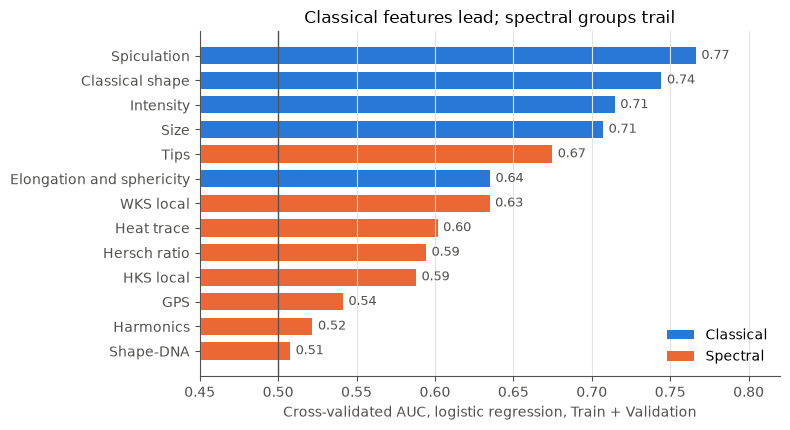

In [2]:
order = groups.sort_values("lr").index; colors = [ORANGE if groups.kind[g] == "spectral" else BLUE for g in order]; fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(order, groups.lr[order].astype(float), color=colors, height=0.7); ax.axvline(0.5, color=INK, lw=1); ax.set(xlim=(0.45, 0.82), xlabel="Cross-validated AUC, logistic regression, Train + Validation", title="Classical features lead; spectral groups trail"); ax.grid(axis="y", visible=False)
for i, g in enumerate(order): ax.annotate(f"{float(groups.lr[g]):.2f}", (float(groups.lr[g]), i), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.barh([0], [0], color=BLUE, label="Classical"); ax.barh([0], [0], color=ORANGE, label="Spectral"); ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.savefig("../docs/assets/lb-groups.png", dpi=150); plt.show()

## 3. Combinations

Every pair of groups (exploratory: the best of 78 pairs is favoured by chance).

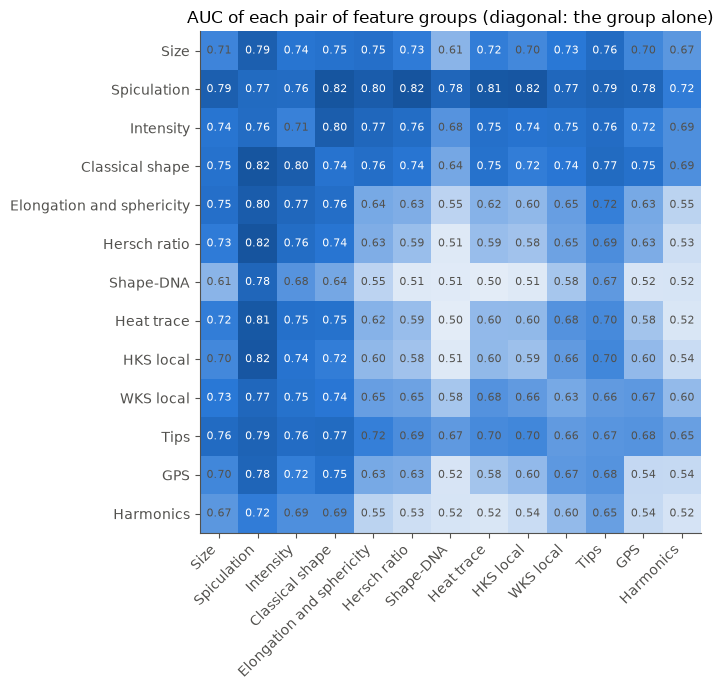

,Logistic,Forest,Features
Everything,0.805,0.803,112.0
All classical,0.837,0.805,21.0
All spectral,0.671,0.661,91.0
Size + spiculation,0.795,0.801,8.0
Size + spiculation + elongation,0.830,0.798,10.0
Size + spiculation + tips,0.801,0.791,16.0
Size + spiculation + tips + elongation,0.832,0.798,18.0


In [3]:
names = list(groups.index); matrix = pd.DataFrame(np.nan, names, names)
for r in pairs.itertuples(): matrix.loc[r.a, r.b] = matrix.loc[r.b, r.a] = r.auc
for g in names: matrix.loc[g, g] = float(groups.lr[g])
fig, ax = plt.subplots(figsize=(8.6, 7)); ax.grid(False); im = ax.imshow(matrix.values, cmap=RAMP, vmin=0.5, vmax=0.85); ax.set_xticks(range(len(names)), names, rotation=45, ha="right"); ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)): ax.text(j, i, f"{matrix.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if matrix.values[i, j] > 0.72 else INK)
ax.set_title("AUC of each pair of feature groups (diagonal: the group alone)"); plt.tight_layout(); plt.savefig("../docs/assets/lb-pairs.png", dpi=150); plt.show()
s2 = sets.copy(); s2.columns = ["Logistic", "Forest", "Features"]; s2.round(3)

**What each group adds.** "Add" puts a group on top of size and spiculation. "Drop" removes it from all features. Intervals are bootstrap 95% over lesions, for one comparison each; 11 additions were tried, so one interval excluding zero is weak evidence.

In [4]:
rows = {g: {"Add: AUC": e.get("add_to_base", {}).get("after"), "Add: gain": e.get("add_to_base", {}).get("gain"), "Add: low": e.get("add_to_base", {}).get("low"), "Add: high": e.get("add_to_base", {}).get("high"), "Drop: AUC lost": e["drop"]["gain"], "Drop: low": e["drop"]["low"], "Drop: high": e["drop"]["high"]} for g, e in effects.items()}
print("Size + spiculation alone, same out-of-fold scores:", round(effects["Hersch ratio"]["add_to_base"]["before"], 3))
pd.DataFrame(rows).T.astype(float).sort_values("Add: gain", ascending=False).round(3)

Size + spiculation alone, same out-of-fold scores: 0.798


,Add: AUC,Add: gain,Add: low,Add: high,Drop: AUC lost,Drop: low,Drop: high
Hersch ratio,0.843,0.045,0.006,0.089,0.002,-0.001,0.006
Heat trace,0.838,0.040,0.004,0.082,0.003,-0.001,0.008
Elongation and sphericity,0.835,0.037,-0.000,0.080,-0.000,-0.005,0.005
HKS local,0.828,0.030,-0.016,0.083,0.003,-0.007,0.013
Classical shape,0.826,0.029,-0.013,0.072,0.002,-0.008,0.011
WKS local,0.811,0.013,-0.029,0.059,-0.002,-0.021,0.016
Tips,0.809,0.011,-0.033,0.057,0.032,-0.005,0.071
GPS,0.807,0.009,-0.026,0.047,-0.003,-0.008,0.001
Shape-DNA,0.790,-0.008,-0.064,0.047,-0.013,-0.041,0.015
Intensity,0.783,-0.015,-0.048,0.016,0.006,-0.019,0.033


## 4. The honest score: selection inside cross-validation

Nested selection of groups:   AUC 0.814 (SD 0.018 over repeats), 4.8 groups on average
Nested selection of features: AUC 0.787 (SD 0.020), 5.9 features on average
Shuffled labels, same pipeline: median 0.502, 95th percentile 0.582, largest of 100 0.685; p < 0.010


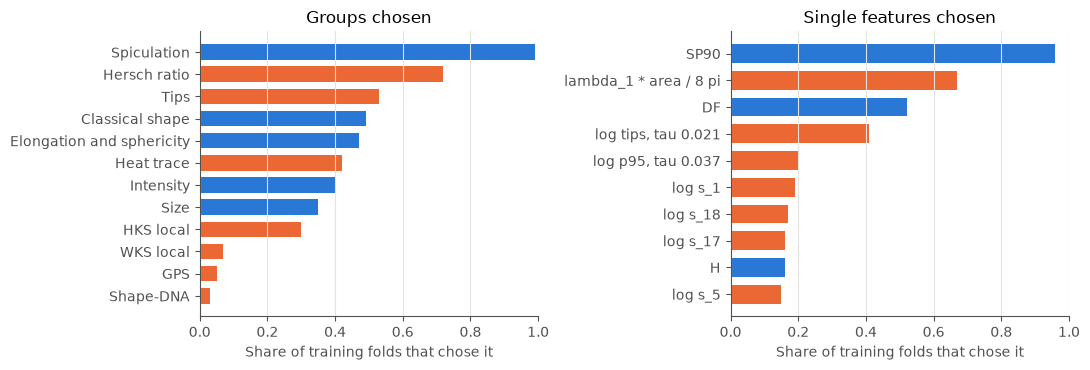

In [5]:
null = np.array(sel["groups"]["null"]); g, f = sel["groups"], sel["features"]
print(f"Nested selection of groups:   AUC {g['auc']:.3f} (SD {g['sd']:.3f} over repeats), {g['size']:.1f} groups on average")
print(f"Nested selection of features: AUC {f['auc']:.3f} (SD {f['sd']:.3f}), {f['size']:.1f} features on average")
print(f"Shuffled labels, same pipeline: median {np.median(null):.3f}, 95th percentile {np.percentile(null, 95):.3f}, largest of {len(null)} {null.max():.3f}; p < {1 / (len(null) + 1):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); a = pd.Series(g["picked"]).sort_values(); ax[0].barh(a.index, a.values, color=[ORANGE if k in lc.SPECTRAL else BLUE for k in a.index], height=0.7); ax[0].set(xlabel="Share of training folds that chose it", title="Groups chosen", xlim=(0, 1)); ax[0].grid(axis="y", visible=False)
b = pd.Series(f["picked"]).sort_values().tail(10); ax[1].barh([k.split(": ")[1] for k in b.index], b.values, color=[ORANGE if k.split(": ")[0] in lc.SPECTRAL else BLUE for k in b.index], height=0.7); ax[1].set(xlabel="Share of training folds that chose it", title="Single features chosen", xlim=(0, 1)); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("../docs/assets/lb-selection.png", dpi=150); plt.show()

## 5. Most useful single features

How often each feature survives an L1-penalised model over 500 bootstraps. Correlated features share credit, so a feature with a low share can still be informative; the sign column shows how often it pointed toward malignant when selected.

,Feature,Selected,Toward malignant when selected,Mean coefficient
0,Spiculation: SP90,0.714,1.0,0.286
1,Elongation and sphericity: log elongation,0.686,0.0,-0.156
2,"Tips: log tips, tau 0.021",0.572,1.0,0.088
3,Intensity: H,0.570,1.0,0.105
4,Spiculation: SPcyl_max_slice_mean,0.532,1.0,0.141
5,Size: log area,0.486,1.0,0.117
6,Size: log volume,0.434,1.0,0.109
7,Spiculation: SPcyl_upper_mean,0.384,1.0,0.092
8,"Tips: log tips, tau 0.012",0.334,1.0,0.039
9,Intensity: AI,0.332,1.0,0.039


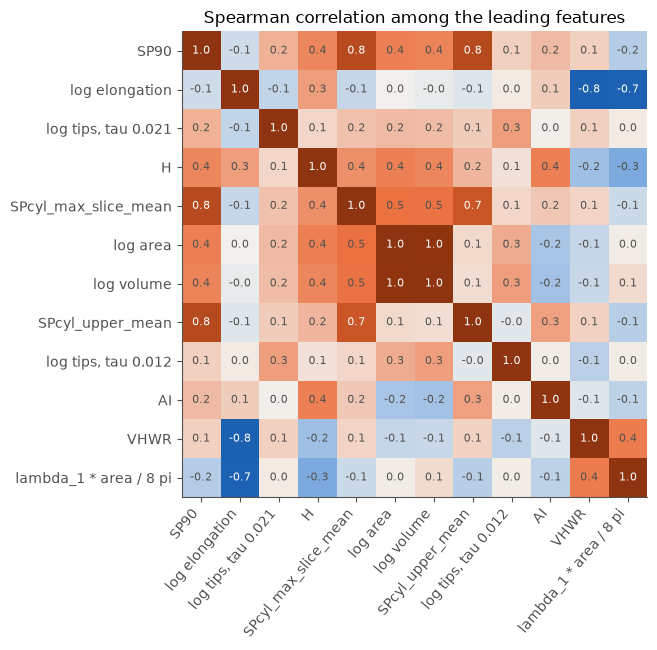

In [6]:
top = stab.head(14).copy(); top["Toward malignant when selected"] = (top.positive / top.selected).round(2); top.columns = ["Feature", "Selected", "Positive", "Mean coefficient", "Toward malignant when selected"]; display(top[["Feature", "Selected", "Toward malignant when selected", "Mean coefficient"]].round(3))
keep = [c for c in stab.feature.head(12)]; corr = table[keep].corr("spearman"); fig, ax = plt.subplots(figsize=(8.2, 6.6)); ax.grid(False); ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1); labels = [k.split(": ")[1] for k in keep]; ax.set_xticks(range(12), labels, rotation=50, ha="right"); ax.set_yticks(range(12), labels)
for i in range(12):
    for j in range(12): ax.text(j, i, f"{corr.values[i, j]:.1f}", ha="center", va="center", fontsize=8, color="white" if abs(corr.values[i, j]) > 0.6 else INK)
ax.set_title("Spearman correlation among the leading features"); plt.tight_layout(); plt.show()

## 6. A small model anyone can read

Four features, chosen by rule: those picked in at least 40% of training folds by nested feature selection. Its coefficients are odds ratios per standard deviation. **Its cross-validated AUC is optimistic**, because the features were picked on these lesions. The nested score of 0.79 above is the fair one. The same four features, fixed now, are the natural candidate for a single test run later.

Chosen: ['Spiculation: SP90', 'Hersch ratio: lambda_1 * area / 8 pi', 'Classical shape: DF', 'Tips: log tips, tau 0.021']


,Odds ratio per SD,"95% CI, low","95% CI, high",Spearman with log volume
Spiculation: SP90,5.05,2.84,11.14,0.40
Hersch ratio: lambda_1 * area / 8 pi,2.42,1.50,4.26,0.08
Classical shape: DF,2.04,1.26,4.01,0.92
"Tips: log tips, tau 0.021",1.55,1.02,2.62,0.19


Cross-validated AUC, optimistic: 0.869; accuracy at 0.5: 0.800; sensitivity 0.840; specificity 0.745

The same features as a depth-2 tree, for reading only:
|--- SP90 <= 2.60
|   |--- lambda_1 * area / 8 pi <= 0.76
|   |   |--- class: 0
|   |--- lambda_1 * area / 8 pi >  0.76
|   |   |--- class: 1
|--- SP90 >  2.60
|   |--- lambda_1 * area / 8 pi <= 0.55
|   |   |--- class: 1
|   |--- lambda_1 * area / 8 pi >  0.55
|   |   |--- class: 1



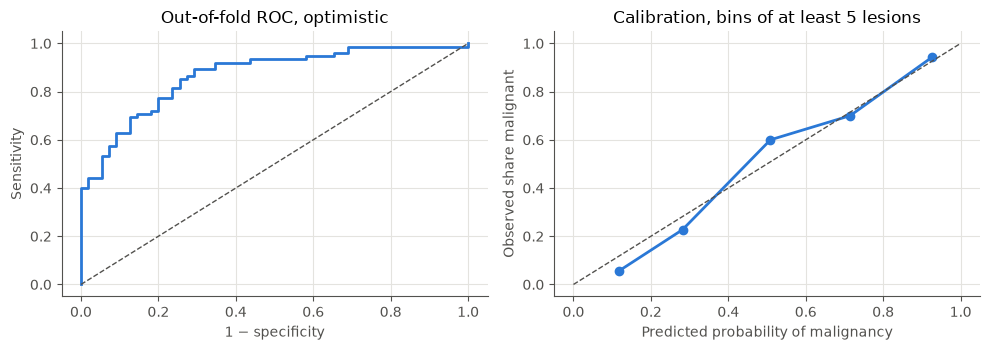

In [7]:
COMPACT = [k for k, v in f["picked"].items() if v >= 0.4]; print("Chosen:", COMPACT); Xc = table[COMPACT].values.astype(float); mean, std = Xc.mean(0), Xc.std(0); Z = (Xc - mean) / std
model = LogisticRegression(max_iter=3000).fit(Z, y); rng = np.random.default_rng(0); boots = []
while len(boots) < 2000:
    i = rng.integers(0, 130, 130)
    if 0 < y[i].sum() < 130: boots.append(LogisticRegression(max_iter=3000).fit(Z[i], y[i]).coef_[0])
boots = np.array(boots); coef = pd.DataFrame({"Odds ratio per SD": np.exp(model.coef_[0]), "95% CI, low": np.exp(np.percentile(boots, 2.5, 0)), "95% CI, high": np.exp(np.percentile(boots, 97.5, 0)), "Spearman with log volume": [spearmanr(Xc[:, j], table["Size: log volume"])[0] for j in range(len(COMPACT))]}, index=COMPACT); display(coef.round(2))
score = lc.oof_mean(Xc, y, 20); full = lc.oof_mean(table[[c for c in table if c.startswith("Size") or c.startswith("Spiculation")]].values.astype(float), y, 20); probabilities = np.zeros(130)
for s in range(20):
    for tr, te in lc.splits(y, s): probabilities[te] += lc.linear().fit(Xc[tr], y[tr]).predict_proba(Xc[te])[:, 1] / 20
print(f"Cross-validated AUC, optimistic: {roc_auc_score(y, score):.3f}; accuracy at 0.5: {((probabilities >= 0.5) == y).mean():.3f}; sensitivity {((probabilities >= 0.5)[y == 1]).mean():.3f}; specificity {((probabilities < 0.5)[y == 0]).mean():.3f}")
tree = DecisionTreeClassifier(max_depth=2, min_samples_leaf=10, random_state=0).fit(table[COMPACT].values, y); print("\nThe same features as a depth-2 tree, for reading only:\n" + export_text(tree, feature_names=[c.split(': ')[1] for c in COMPACT]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6)); f_, t_, _ = roc_curve(y, score); ax[0].plot(f_, t_, color=BLUE, lw=2); ax[0].plot([0, 1], [0, 1], color=INK, lw=1, ls="--"); ax[0].set(xlabel="1 − specificity", ylabel="Sensitivity", title="Out-of-fold ROC, optimistic"); edges = np.linspace(0, 1, 6); mid, obs = [], []
for a_, b_ in zip(edges[:-1], edges[1:]):
    m = (probabilities >= a_) & (probabilities < b_ + (b_ == 1))
    if m.sum() >= 5: mid.append(probabilities[m].mean()); obs.append(y[m].mean())
ax[1].plot(mid, obs, "o-", color=BLUE, lw=2, ms=6); ax[1].plot([0, 1], [0, 1], color=INK, lw=1, ls="--"); ax[1].set(xlabel="Predicted probability of malignancy", ylabel="Observed share malignant", title="Calibration, bins of at least 5 lesions"); plt.tight_layout(); plt.show()

## 7. Explaining single lesions

Because the model is linear, each prediction is a sum: baseline plus one contribution per feature, each being coefficient × standardised value. Bars right of zero push toward malignant. Lesions are the highest- and lowest-scored of each class among the 10 stored Train samples, a rule-based pick; the model that scores each was fitted without it. Orange points on the surfaces are tips at $\tau=0.021$, one of the model's features.

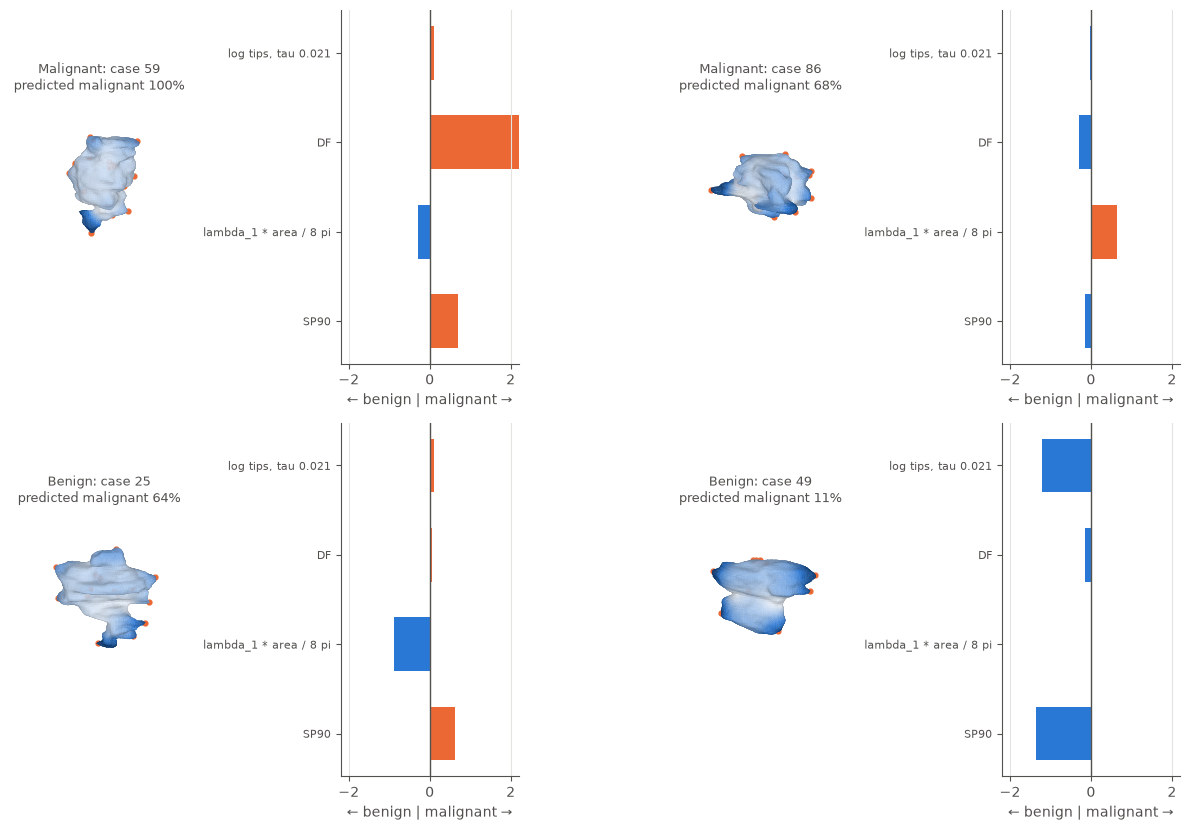

In [8]:
store = np.load("../results/lb-roundness/sample_meshes.npz"); keys = [k[:-5] for k in store.files if k.endswith("_case")]; cases = {k: int(store[k + "_case"]) for k in keys}
assert all(table.split[c] == "Train" and table.case[c] == c for c in cases.values())
def explain(c):
    tr = np.arange(130) != c; m, s = Xc[tr].mean(0), Xc[tr].std(0); fit = LogisticRegression(max_iter=3000).fit((Xc[tr] - m) / s, y[tr]); z = (Xc[c] - m) / s
    return fit.intercept_[0], fit.coef_[0] * z, fit.predict_proba(z[None])[0, 1]
picked = []
for label in (1, 0):
    group = sorted([k for k, c in cases.items() if y[c] == label], key=lambda k: explain(cases[k])[2]); picked += [group[-1], group[0]]
fig = plt.figure(figsize=(12, 8.4)); short = [c.split(": ")[1] for c in COMPACT]; j = int(np.argmin(np.abs(TAUS - 0.021)))
for i, k in enumerate(picked):
    m = trimesh.Trimesh(store[k + "_vertices"].astype(float), store[k + "_faces"], process=False); L, Mm = compute_laplace_beltrami_operator(m); lam, phi = compute_eigendecomposition(L, Mm, k=200); h = compute_hks(lam * m.area, phi * np.sqrt(m.area), TAUS)[:, j]; tips = local_maxima(h, m)
    ax = fig.add_subplot(2, 4, 2 * i + 1, projection="3d"); draw_mesh(ax, m, h, RAMP, np.percentile(h, 2), np.percentile(h, 98)); ax.scatter(*m.vertices[tips].T, color=ORANGE, s=12, depthshade=False)
    base, parts, p = explain(cases[k]); cls = "Malignant" if y[cases[k]] else "Benign"; ax.set_title(f"{cls}: case {cases[k]}\npredicted malignant {p:.0%}", fontsize=9, color=INK)
    bar = fig.add_subplot(2, 4, 2 * i + 2); bar.barh(short, parts, color=[ORANGE if v > 0 else BLUE for v in parts], height=0.6); bar.axvline(0, color=INK, lw=1); bar.set(xlim=(-2.2, 2.2), xlabel="← benign | malignant →"); bar.grid(axis="y", visible=False); bar.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig("../docs/assets/lb-3d-explanations.png", dpi=130); plt.show()

### Where the model fails

The worst out-of-fold errors among all 130 lesions, by how confidently they were wrong.

In [9]:
wrong = np.abs(probabilities - y); idx = np.argsort(-wrong)[:8]; display(pd.DataFrame({"Split": table.split[idx].values, "Case": table.case[idx].values, "Class": np.where(y[idx], "Malignant", "Benign"), "Predicted malignant": probabilities[idx].round(2), **{c.split(": ")[1]: Z[idx, n].round(2) for n, c in enumerate(COMPACT)}, "log volume z": ((table["Size: log volume"].values[idx] - table["Size: log volume"].mean()) / table["Size: log volume"].std()).round(2)}))
print(f"Errors: benign lesions called malignant have mean volume z {((table['Size: log volume'] - table['Size: log volume'].mean()) / table['Size: log volume'].std())[(probabilities >= 0.5) & (y == 0)].mean():.2f}; malignant called benign {((table['Size: log volume'] - table['Size: log volume'].mean()) / table['Size: log volume'].std())[(probabilities < 0.5) & (y == 1)].mean():.2f}.")

,Split,Case,Class,Predicted malignant,SP90,lambda_1 * area / 8 pi,DF,"log tips, tau 0.021",log volume z
0,Train,81,Malignant,0.00,-1.68,-1.66,-0.50,-1.85,-1.25
1,Train,50,Benign,0.84,0.84,-1.22,-0.25,1.71,-0.62
2,Validation,105,Benign,0.82,-0.28,0.51,0.77,0.53,1.60
3,Train,40,Malignant,0.20,-0.12,-1.74,-0.30,-0.04,-0.41
4,Train,84,Benign,0.80,-0.38,0.80,0.17,1.04,0.92
5,Train,37,Malignant,0.21,-0.61,-0.15,-0.15,-1.43,0.25
6,Train,56,Malignant,0.23,-0.78,-0.02,-0.20,-0.68,0.05
7,Validation,101,Benign,0.77,-0.23,0.67,0.29,0.25,0.94


Errors: benign lesions called malignant have mean volume z 0.32; malignant called benign -0.34.


## 8. Conclusions

- **Fair performance is about 0.81.** Selecting groups inside cross-validation gives AUC 0.81, against 0.58 at the 95th percentile with shuffled labels (p < 0.01). Single-feature selection gives 0.79. These are Train+Validation estimates; Test has not been used.
- **Spiculation is the core.** It is chosen in 99% of folds, and it is the only group whose removal clearly lowers the full model (0.071, interval 0.022 to 0.125). It uses image gradients, so this is not a purely shape-based result.
- **Spectral features alone are weak, but one adds to spiculation.** All spectral groups together reach 0.67. The Hersch ratio, a single number, adds 0.045 on top of size and spiculation (interval 0.006 to 0.089), is chosen in 72% of folds, and has an odds ratio of 2.4 per SD (1.5 to 4.3). With 11 additions tried, this is promising, not established. Heat trace is similar (0.040), and overlaps with it.
- **What the Hersch ratio means here.** Higher means closer to round in the spectral sense, and those lesions are more often malignant, along with less elongated ones. Benign lesions here tend to be more elongated. It runs against the expectation that malignant lesions are more irregular, though irregularity and elongation are different things. Treat it as a hypothesis until tested on held-out data.
- **More features is not better.** Everything together (112 features, 0.81) scores below all classical features (21, 0.84), and Shape-DNA and harmonics add nothing, or subtract, on top of the base. On 130 lesions, a handful of features is what the data can support.
- **Size enters more than one way.** `DF` is the volume difference from a fitted ellipsoid in mm³, with Spearman 0.92 against volume, so in the small model it mostly acts as size.
- **Single predictions can be explained.** The small model's prediction is a sum of readable contributions, shown above with each lesion's surface. Its errors are not one simple pattern: the most confident error is a small, low-spiculation malignant lesion.

## 9. Protocol

Train+Validation only (130 lesions); malignant is positive. Five-fold CV repeated 20 times; logistic regression standardised inside each fold; nested forward selection; 100 label permutations of the nested pipeline. Features were computed from stored results of earlier steps, on clean surfaces. No training on GPU and no Kaggle kernel. Stored: `results/lb-classification/`. No challenge benchmark, as no final model was run on Test.

## 10. Open issues

- **One test run.** The four features above, or a choice agreed in advance, can be fitted on all 130 and scored once on Test. Not done, and it can only be done once.
- **Predicted masks.** All of this uses true masks. `lb-stability.ipynb` shows shape features lose much of their rank on predicted masks, so a full pipeline would score lower.
- **Elongation direction.** Whether malignant lesions being less elongated reflects biology, annotation or scanning is untested.